Hotel Cancellation 

In [1]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns

### Retrieving data set from github repository

In [2]:
url = 'https://raw.githubusercontent.com/sascott9655/ADS-505-Hotel_Bookings_Project/main/hotel_bookings.csv'
df = pd.read_csv(url)
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,no,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,7/1/2015
1,Resort Hotel,no,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,7/1/2015
2,Resort Hotel,no,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,7/2/2015
3,Resort Hotel,no,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,7/2/2015
4,Resort Hotel,no,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,7/3/2015


### Sanity Check

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  object 
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

In [4]:
df["is_canceled"] = (df["is_canceled"] == "yes").astype(int) # yes/no -> 1/0 (this will matter for modeling later on!)
missing = df.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print("\nMissing values:")
print(pd.DataFrame({"count": missing, "percent": (missing / len(df) * 100).round(1)}))
df.describe().T.round(2)


Missing values:
           count  percent
company   112593     94.3
agent      16340     13.7
country      488      0.4
children       4      0.0


,count,mean,std,min,25%,50%,75%,max
is_canceled,119390.0,0.37,0.48,0.00,0.00,0.00,1.0,1.0
lead_time,119390.0,104.01,106.86,0.00,18.00,69.00,160.0,737.0
arrival_date_year,119390.0,2016.16,0.71,2015.00,2016.00,2016.00,2017.0,2017.0
arrival_date_week_number,119390.0,27.17,13.61,1.00,16.00,28.00,38.0,53.0
arrival_date_day_of_month,119390.0,15.80,8.78,1.00,8.00,16.00,23.0,31.0
stays_in_weekend_nights,119390.0,0.93,1.00,0.00,0.00,1.00,2.0,19.0
stays_in_week_nights,119390.0,2.50,1.91,0.00,1.00,2.00,3.0,50.0
adults,119390.0,1.86,0.58,0.00,2.00,2.00,2.0,55.0
children,119386.0,0.10,0.40,0.00,0.00,0.00,0.0,10.0
babies,119390.0,0.01,0.10,0.00,0.00,0.00,0.0,10.0


In [5]:
df = df.drop_duplicates()
df.shape

(87396, 32)

In [6]:
#children impute missing value with zero(since they are so few missing values and most of the data shows that customers are not children 
#and/or with children)
impute_with_zero = (df['children'].isna() == True)
impute_with_zero = impute_with_zero[impute_with_zero == True]
df.loc[impute_with_zero.index, 'children'] = 0
df['children'].isna().sum()
 
df['country'] = df['country'].fillna('Unknown') #fill it with unknown as it shouldn't impact the data too much
df['country'].isna().sum()

df["has_company"] = df["company"].notna().astype(int)
df["has_company"]

df["has_agent"] = df["agent"].notna().astype(int) 
df["has_agent"]

df = df.drop(columns=["agent", "company"])

In [7]:
df.isna().sum() #no more missing data!!!

hotel                             0
is_canceled                       0
lead_time                         0
arrival_date_year                 0
arrival_date_month                0
arrival_date_week_number          0
arrival_date_day_of_month         0
stays_in_weekend_nights           0
stays_in_week_nights              0
adults                            0
children                          0
babies                            0
meal                              0
country                           0
market_segment                    0
distribution_channel              0
is_repeated_guest                 0
previous_cancellations            0
previous_bookings_not_canceled    0
reserved_room_type                0
assigned_room_type                0
booking_changes                   0
deposit_type                      0
days_in_waiting_list              0
customer_type                     0
adr                               0
required_car_parking_spaces       0
total_of_special_requests   

In [8]:
df = df[(df["adults"] + df["children"] + df["babies"]) > 0] #gets rid of rows where there was no people tracked
df.shape

(87230, 32)

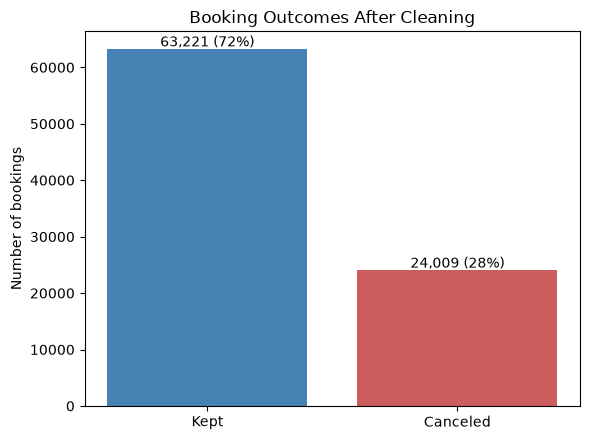

In [9]:
counts = df["is_canceled"].value_counts().sort_index()
plt.figure(figsize=(6, 4.5))
bars = plt.bar(["Kept", "Canceled"], counts.values, color=["steelblue", "indianred"])
for bar, n in zip(bars, counts.values):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 500,
        f"{n:,} ({n / counts.sum():.0%})", ha="center")
plt.title("Booking Outcomes After Cleaning")
plt.ylabel("Number of bookings")
plt.tight_layout()
plt.show()

In [10]:
# Was there a deposit for the booking? If so, what kind?
df['deposit_type'].value_counts().to_frame()

,count
deposit_type,
No Deposit,86085
Non Refund,1038
Refundable,107


### Feature Engineering

In [11]:
#dropping these two columns as the information they provid
#does not seem significant enough considering we have
#arrival_date_year and arrival_date_month
#dropping reservation_status and reservation_status_date because both of these columns allude to directly
#predicting the target variable is_canceled which we do not want a model with strong features that tell us
#the outcome based on these two features alone (not helpful for the business to improve hotel cancellation rate)
df = df.drop(columns=['arrival_date_week_number','arrival_date_day_of_month', 'assigned_room_type',
                     'reservation_status','reservation_status_date'])
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,...,reserved_room_type,booking_changes,deposit_type,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,has_company,has_agent
0,Resort Hotel,0,342,2015,July,0,0,2,0.0,0,...,C,3,No Deposit,0,Transient,0.0,0,0,0,0
1,Resort Hotel,0,737,2015,July,0,0,2,0.0,0,...,C,4,No Deposit,0,Transient,0.0,0,0,0,0
2,Resort Hotel,0,7,2015,July,0,1,1,0.0,0,...,A,0,No Deposit,0,Transient,75.0,0,0,0,0
3,Resort Hotel,0,13,2015,July,0,1,1,0.0,0,...,A,0,No Deposit,0,Transient,75.0,0,0,0,1
4,Resort Hotel,0,14,2015,July,0,2,2,0.0,0,...,A,0,No Deposit,0,Transient,98.0,0,1,0,1


In [12]:
#Guillermo's feature: 
df['length_of_stay'] = df['stays_in_weekend_nights'] + df['stays_in_week_nights']
df[['stays_in_weekend_nights', 'stays_in_week_nights', 'length_of_stay']].head(30)
df.drop(columns=['stays_in_weekend_nights', 'stays_in_week_nights'])

In [13]:
#for features stays_in_weekend_nights and stays_in_week_nights we can feature engineer these two columns into 
#one where it is a binary feature on whether they stay the weekend or not
df['stays_in_weekend_nights'].value_counts()
weekend_nights_yes = df['stays_in_weekend_nights'] > 0
weekend_nights_yes = weekend_nights_yes[weekend_nights_yes == True]
df.loc[weekend_nights_yes.index, 'stays_in_weekend_nights'] = 1
df['stays_in_weekend_nights'].value_counts()

#drop stay_in_week_nights column as it is no longer needed
df = df.drop(columns=['stays_in_week_nights'])
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,stays_in_weekend_nights,adults,children,babies,meal,...,reserved_room_type,booking_changes,deposit_type,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,has_company,has_agent
0,Resort Hotel,0,342,2015,July,0,2,0.0,0,BB,...,C,3,No Deposit,0,Transient,0.0,0,0,0,0
1,Resort Hotel,0,737,2015,July,0,2,0.0,0,BB,...,C,4,No Deposit,0,Transient,0.0,0,0,0,0
2,Resort Hotel,0,7,2015,July,0,1,0.0,0,BB,...,A,0,No Deposit,0,Transient,75.0,0,0,0,0
3,Resort Hotel,0,13,2015,July,0,1,0.0,0,BB,...,A,0,No Deposit,0,Transient,75.0,0,0,0,1
4,Resort Hotel,0,14,2015,July,0,2,0.0,0,BB,...,A,0,No Deposit,0,Transient,98.0,0,1,0,1


In [14]:
#for features children and babies consider combining them into one group since individual they act the same
#(running this code multiple times will change results
df['children'] = df['children'] + df['babies']
df['children'] = df['children'].astype('int')

df = df.drop(columns=['babies'])
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,stays_in_weekend_nights,adults,children,meal,country,...,reserved_room_type,booking_changes,deposit_type,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,has_company,has_agent
0,Resort Hotel,0,342,2015,July,0,2,0,BB,PRT,...,C,3,No Deposit,0,Transient,0.0,0,0,0,0
1,Resort Hotel,0,737,2015,July,0,2,0,BB,PRT,...,C,4,No Deposit,0,Transient,0.0,0,0,0,0
2,Resort Hotel,0,7,2015,July,0,1,0,BB,GBR,...,A,0,No Deposit,0,Transient,75.0,0,0,0,0
3,Resort Hotel,0,13,2015,July,0,1,0,BB,GBR,...,A,0,No Deposit,0,Transient,75.0,0,0,0,1
4,Resort Hotel,0,14,2015,July,0,2,0,BB,GBR,...,A,0,No Deposit,0,Transient,98.0,0,1,0,1


Columns like meal and country need to be one hot-encoded!

In [15]:
top_countries = df["country"].value_counts().nlargest(10).index
#I like the idea of having an other column for countries that do not appear in the data set often
df["country"] = df["country"].where(df["country"].isin(top_countries), "Other")
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,stays_in_weekend_nights,adults,children,meal,country,...,reserved_room_type,booking_changes,deposit_type,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,has_company,has_agent
0,Resort Hotel,0,342,2015,July,0,2,0,BB,PRT,...,C,3,No Deposit,0,Transient,0.0,0,0,0,0
1,Resort Hotel,0,737,2015,July,0,2,0,BB,PRT,...,C,4,No Deposit,0,Transient,0.0,0,0,0,0
2,Resort Hotel,0,7,2015,July,0,1,0,BB,GBR,...,A,0,No Deposit,0,Transient,75.0,0,0,0,0
3,Resort Hotel,0,13,2015,July,0,1,0,BB,GBR,...,A,0,No Deposit,0,Transient,75.0,0,0,0,1
4,Resort Hotel,0,14,2015,July,0,2,0,BB,GBR,...,A,0,No Deposit,0,Transient,98.0,0,1,0,1


In [ ]:
#Correlation matrix: 


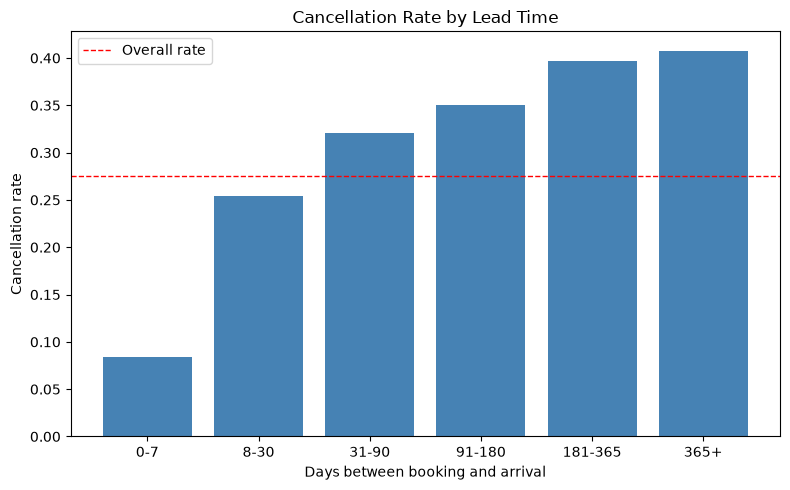

           count  cancel_rate
lead_time                    
0-7        18203        0.084
8-30       16326        0.254
31-90      22720        0.320
91-180     18224        0.350
181-365    11193        0.397
365+         564        0.408


In [18]:
#Nice visual to show likelihood of cancellation based on how many days passed by.
lead_bins = pd.cut(df["lead_time"], bins=[-1, 7, 30, 90, 180, 365, 800],
                  labels=["0-7", "8-30", "31-90", "91-180", "181-365","365+"])
lead_rates = df.groupby(lead_bins, observed=True)["is_canceled"].agg(count="size", cancel_rate="mean")
plt.figure(figsize=(8, 5))
plt.bar(lead_rates.index.astype(str), lead_rates["cancel_rate"], color="steelblue")
plt.axhline(df["is_canceled"].mean(), color="red", linestyle="--", linewidth=1,label="Overall rate")
plt.title("Cancellation Rate by Lead Time")
plt.xlabel("Days between booking and arrival")
plt.ylabel("Cancellation rate")
plt.legend()
plt.tight_layout()
plt.show()
print(lead_rates.round(3))

In [20]:
df.shape

(87230, 25)

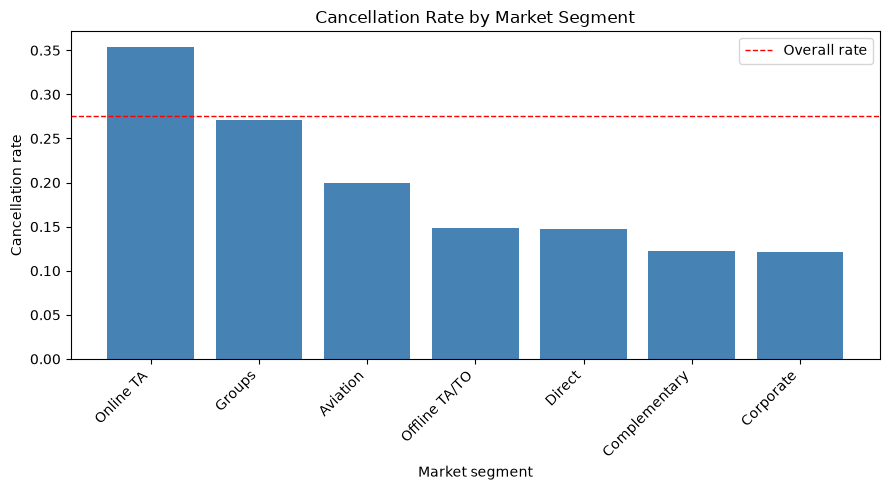

                count  cancel_rate
market_segment                    
Online TA       51553        0.354
Groups           4922        0.271
Aviation          226        0.199
Offline TA/TO   13855        0.148
Direct          11780        0.147
Complementary     692        0.123
Corporate        4200        0.121


In [22]:
seg_rates = (df.groupby("market_segment")["is_canceled"].agg(count="size",
            cancel_rate="mean").query("count > 100").sort_values("cancel_rate", ascending=False)) 
plt.figure(figsize=(9, 5))
plt.bar(seg_rates.index, seg_rates["cancel_rate"], color="steelblue")
plt.axhline(df["is_canceled"].mean(), color="red", linestyle="--", linewidth=1,label="Overall rate")
plt.title("Cancellation Rate by Market Segment")
plt.xlabel("Market segment")
plt.ylabel("Cancellation rate")
plt.xticks(rotation=45, ha="right")
plt.legend()
plt.tight_layout()
plt.show()
print(seg_rates.round(3))